# Actividad :  Resolución de problema mediante búsqueda heurística





Actualización:

*   2026/02/16, Fichero creado






## Importante

El código siguiente es el que debe usarse para la ejecución de la actividad.
En caso de requerir modificaciones se subirán ficheros de sustitución al aula de la asignatura


In [66]:
%pip install -q simpleai pydot graphviz

Note: you may need to restart the kernel to use updated packages.


In [67]:
import shutil, sys
print(sys.executable)
print(shutil.which('dot'))

/home/abarra/anaconda3/envs/pln/bin/python
/usr/bin/dot


In [68]:
#!/usr/bin/env python
# coding: utf-8

# 2024 Modified by: Alejandro Cervantes

from __future__ import print_function

import math
import shutil
from IPython.display import Image, display
from simpleai.search.viewers import BaseViewer,ConsoleViewer
from simpleai.search import SearchProblem, astar, breadth_first, depth_first, uniform_cost



class GameWalkPuzzle(SearchProblem):

    def __init__(self, board, costs, heuristic_number):
        self.board = board
        self.goal = (0, 0)
        self.costs = costs
        self.heuristic_number = heuristic_number
        for y in range(len(self.board)):
            for x in range(len(self.board[y])):
                if self.board[y][x].lower() == "t":
                    self.initial = (x, y)
                elif self.board[y][x].lower() == "p":
                    self.goal = (x, y)

        super(GameWalkPuzzle, self).__init__(initial_state=self.initial)

    def actions(self, state):
        actions = []
        for action in list(self.costs.keys()):
            newx, newy = self.result(state, action)
            if self.board[newy][newx] != "#":
                actions.append(action)
        # print(actions)
        return actions

    def result(self, state, action):
        x, y = state

        if action.count("up"):
            y -= 1
        if action.count("down"):
            y += 1
        if action.count("left"):
            x -= 1
        if action.count("right"):
            x += 1

        new_state = (x, y)
        # print(new_state)
        return new_state

    def is_goal(self, state):
        return state == self.goal

    def cost(self, state, action, state2):
        return self.costs[action]

    # Esta función heurística es la distancia entre el estado actual
    # el objetivo (único) identificado como self.goal
    def heuristic1(self, state):
        x, y = state
        gx, gy = self.goal
        return abs(x - gx) + abs(y - gy)

    def heuristic2(self, state):
        x, y = state
        gx, gy = self.goal
        return max(abs(x - gx),abs(y - gy))

    def heuristic3(self, state):
        x, y = state
        gx, gy = self.goal
        return 2*(abs(x - gx) + abs(y - gy))

    def heuristic(self,state):
      if self.heuristic_number == 1:
          return self.heuristic1(state)
      elif self.heuristic_number == 2:
          return self.heuristic2(state)
      elif self.heuristic_number == 3:
          return self.heuristic3(state)
      else:
        raise Exception("El número de la función heurística debe estar entre 1 y 3. Revise la inicialización del problema.")

def searchInfo (problem,result,use_viewer):
    def getTotalCost (problem,result):
        originState = problem.initial_state
        totalCost = 0
        for action,endingState in result.path():
            if action is not None:
                totalCost += problem.cost(originState,action,endingState)
                originState = endingState
        return totalCost


    res = "Total length of solution: {0}\n".format(len(result.path()))
    res += "Total cost of solution: {0}\n".format(getTotalCost(problem,result))

    if use_viewer:
        stats = [{'name': stat.replace('_', ' '), 'value': value}
                         for stat, value in list(use_viewer.stats.items())]

        exp = [ {'name' : 'expanded nodes', 'value' : s['value']-1 } for s in stats if s['name'] == 'visited nodes' ]
        stats = stats + exp

        for s in stats:
            res+= '{0}: {1}\n'.format(s['name'],s['value'])
    return res


def resultado_experimento(problem,MAP,result,used_viewer):
    path = [x[1] for x in result.path()]

    for y in range(len(MAP)):
        for x in range(len(MAP[y])):
            if (x, y) == problem.initial:
                print("T", end='')
            elif (x, y) == problem.goal:
                print("P", end='')
            elif (x, y) in path:
                print("·", end='')
            else:
                print(MAP[y][x], end='')
        print()

    info=searchInfo(problem,result,used_viewer)
    print(info)

# Muestra la traza de la búsqueda (ConsoleViewer no interactivo) y guarda los
# nodos elegidos para dibujar al final el árbol completo de nodos expandidos.
class ExpandedTreeViewer(ConsoleViewer):

    def __init__(self, interactive=False):
        super(ExpandedTreeViewer, self).__init__(interactive=interactive)
        self.chosen_nodes = []
        self.solution_node = None

    def handle_chosen_node(self, node, is_goal=None):
        super(ExpandedTreeViewer, self).handle_chosen_node(node, is_goal)
        self.chosen_nodes.append(node)

    # rankdir: 'LR' dibuja el árbol de izquierda a derecha, 'TB' de arriba abajo
    def build_expanded_tree(self, title, rankdir='LR'):
        from pydot import Dot, Edge, Node

        solution_path = set()
        node = self.solution_node
        while node is not None:
            solution_path.add(id(node))
            node = node.parent

        graph = Dot(graph_type='digraph', label=title, labelloc='t', rankdir=rankdir)
        # Se usa id(node) porque dos nodos distintos pueden tener el mismo estado
        for order, node in enumerate(self.chosen_nodes, 1):
            color = self.solution_color if id(node) in solution_path else self.fringe_color
            graph.add_node(Node(str(id(node)),
                                label='{0}\n{1}'.format(order, node.state_representation()),
                                style='filled',
                                shape='circle',
                                fillcolor=color,
                                fontsize=self.font_size))
            if node.parent is not None:
                graph.add_edge(Edge(str(id(node.parent)),
                                    str(id(node)),
                                    label=node.action_representation(),
                                    fontsize=self.font_size))
        return graph

    def show_expanded_tree(self, title, rankdir='LR'):
        if shutil.which('dot') is None:
            print("No se puede dibujar el árbol: falta el ejecutable 'dot' de Graphviz en el PATH")
            return
        display(Image(self.build_expanded_tree(title, rankdir).create_png()))


# rankdirs: orientación del árbol por algoritmo, p.ej. {'depth_first': 'TB'}.
# Por defecto 'LR'; 'TB' para los árboles muy alargados
def main(MAP_ASCII,COSTS,algorithms,heuristic_number=1,viewer_factory=BaseViewer,rankdirs=None):
    MAP = [list(x) for x in MAP_ASCII.split("\n") if x]
    #print("MAP after process -> ", MAP)
    for algorithm in algorithms:
      problem = GameWalkPuzzle(MAP,COSTS,heuristic_number)
      used_viewer=viewer_factory()
      # Probad también ConsoleViewer para depurar

      # Mostramos tres experimentos
      print ("Experimento con algoritmo {}:".format(algorithm))

      result = algorithm(problem, graph_search=True,viewer=used_viewer)
      resultado_experimento(problem,MAP,result,used_viewer)
      if isinstance(used_viewer,ExpandedTreeViewer):
          rankdir=(rankdirs or {}).get(algorithm.__name__,'LR')
          used_viewer.show_expanded_tree("Nodos expandidos: {} (el número indica el orden)".format(algorithm.__name__),rankdir)





Aquí se define el mapa base para todos los casos.

In [69]:
# Mapa para todos los casos

MAP_ASCII_ORIG = """
#########
# T     #
# # ### #
#   #P  #
# ##    #
#       #
#       #
#########
"""


Experimento con algoritmo <function breadth_first at 0x7d1e6c134900>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <(4, 1)

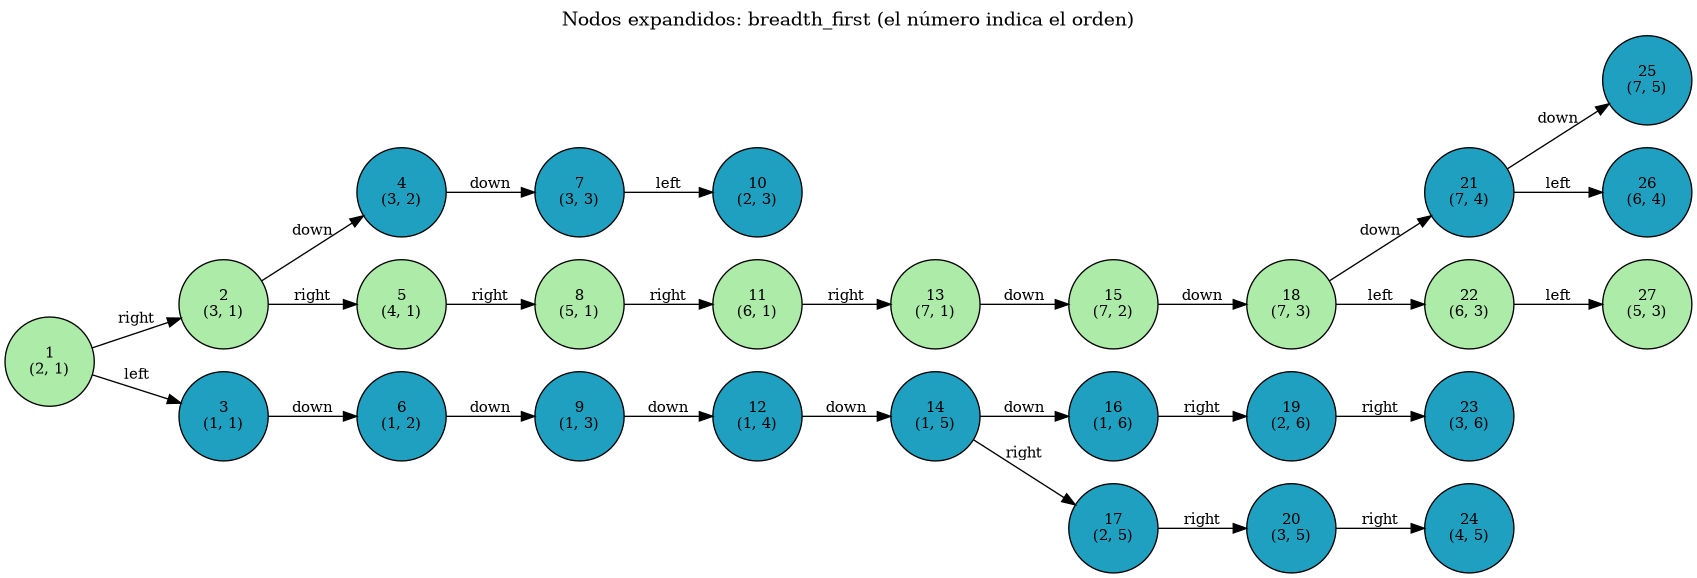

Experimento con algoritmo <function depth_first at 0x7d1e6c134b80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(1, 1)>, Node <(3, 1)>]
EVENT: chosen_node
Chosen node: Node <(1, 1)>
Not goal
EVENT: expanded
Expanded [Node <(1, 1)>]
Successors: [[Node <(1, 2)>, Node <(2, 1)>]

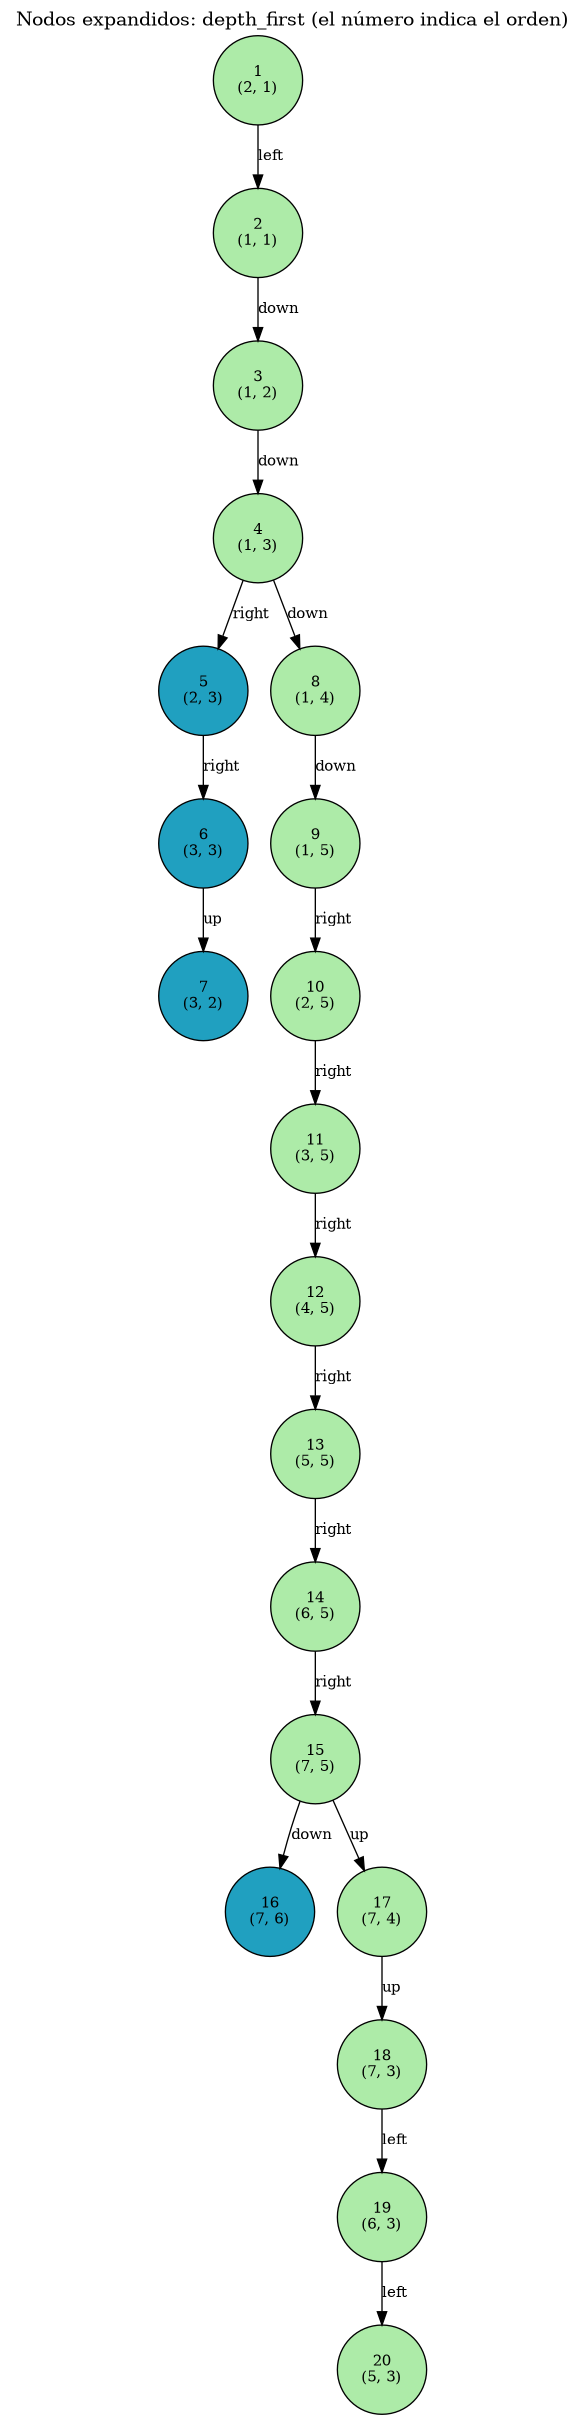

In [70]:

# Configuración y llamada para el caso 1
# Se ejecutan los algoritmos de búsqueda en amplitud y búsqueda en profundidad

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 1.0,
}

algorithms=(breadth_first,depth_first)
main (MAP_ASCII,COSTS,algorithms,viewer_factory=ExpandedTreeViewer,rankdirs={'depth_first': 'TB'})

Experimento con algoritmo <function breadth_first at 0x7d1e6c134900>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <(4, 1)

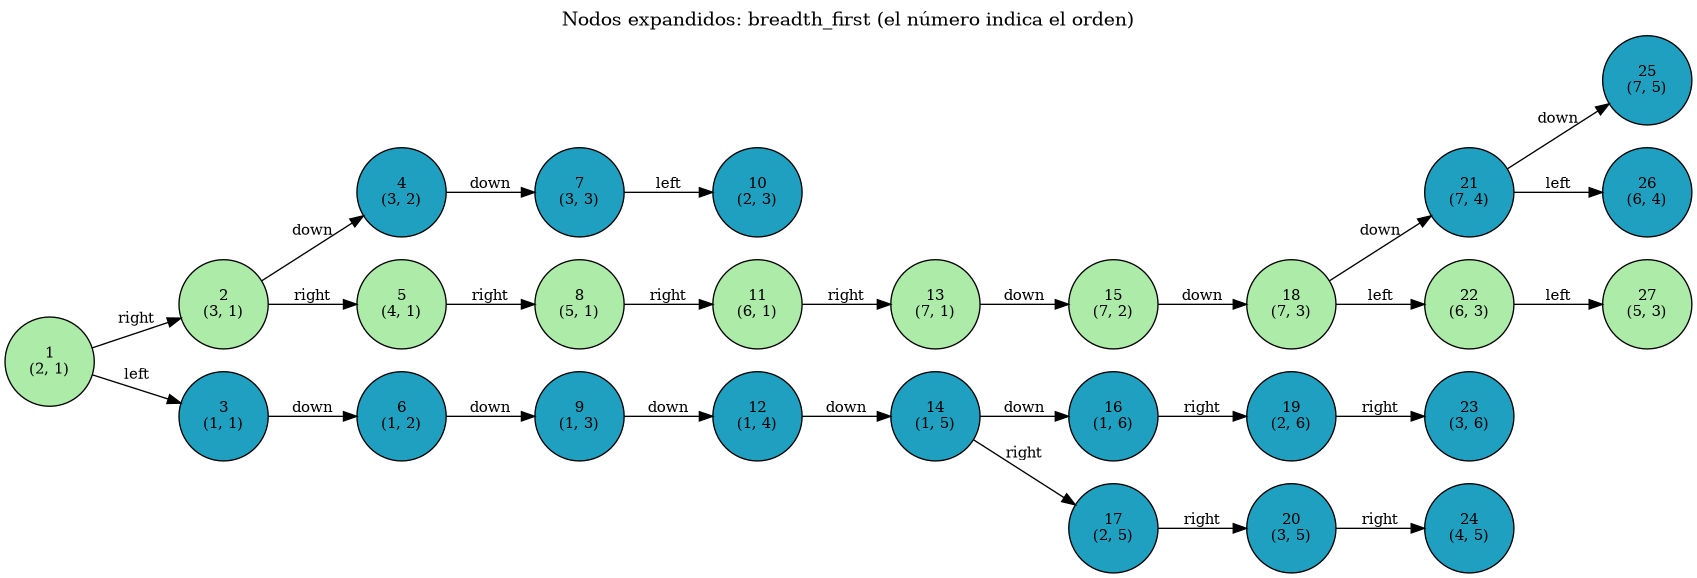

Experimento con algoritmo <function uniform_cost at 0x7d1e6c135940>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <(4, 1)>

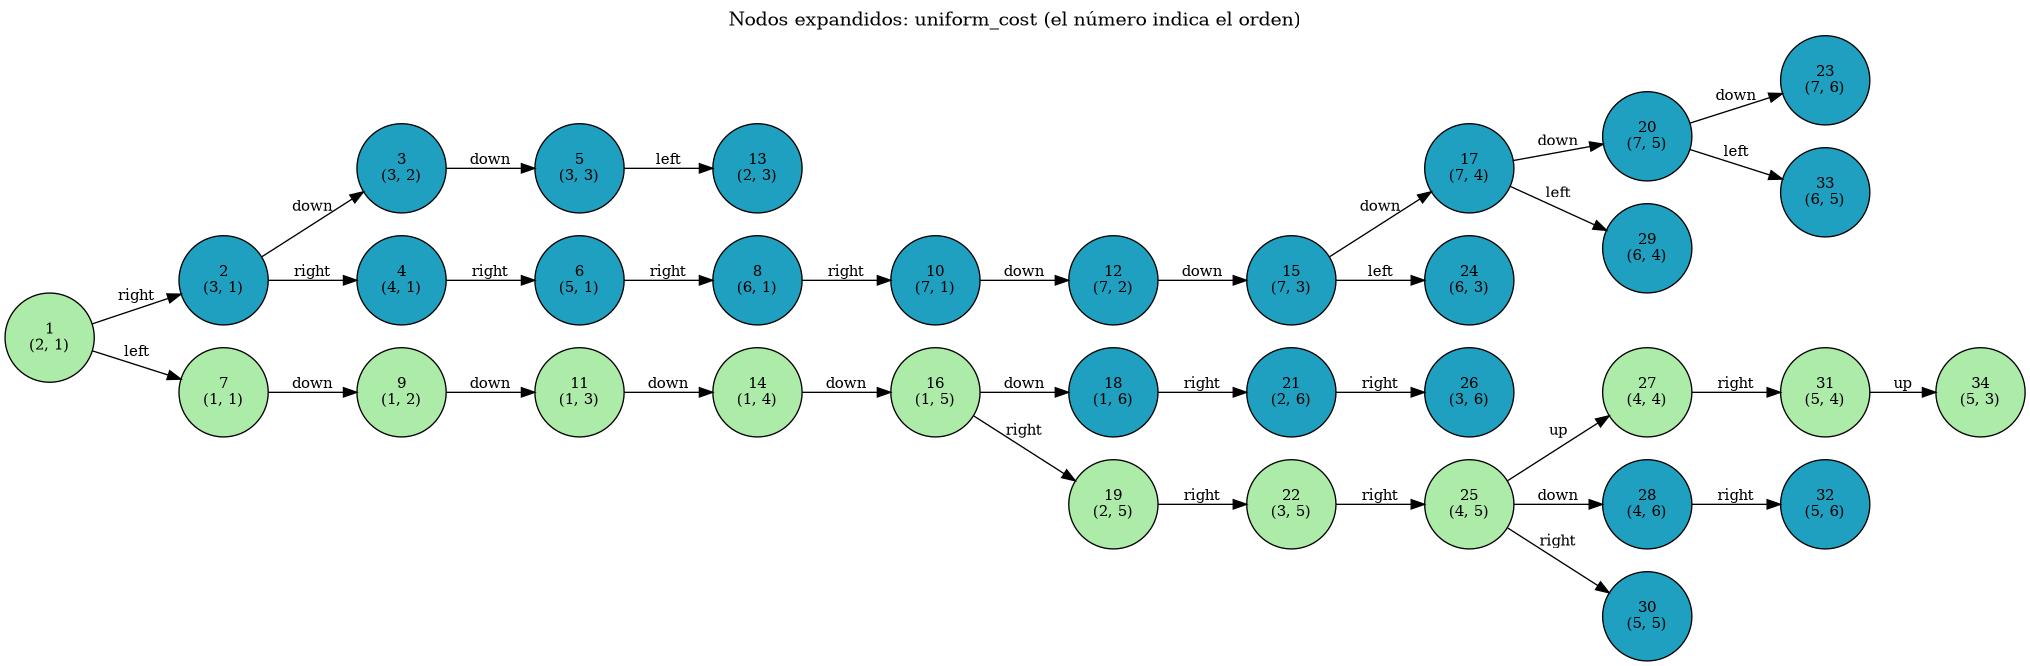

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <(4, 1)>, Node 

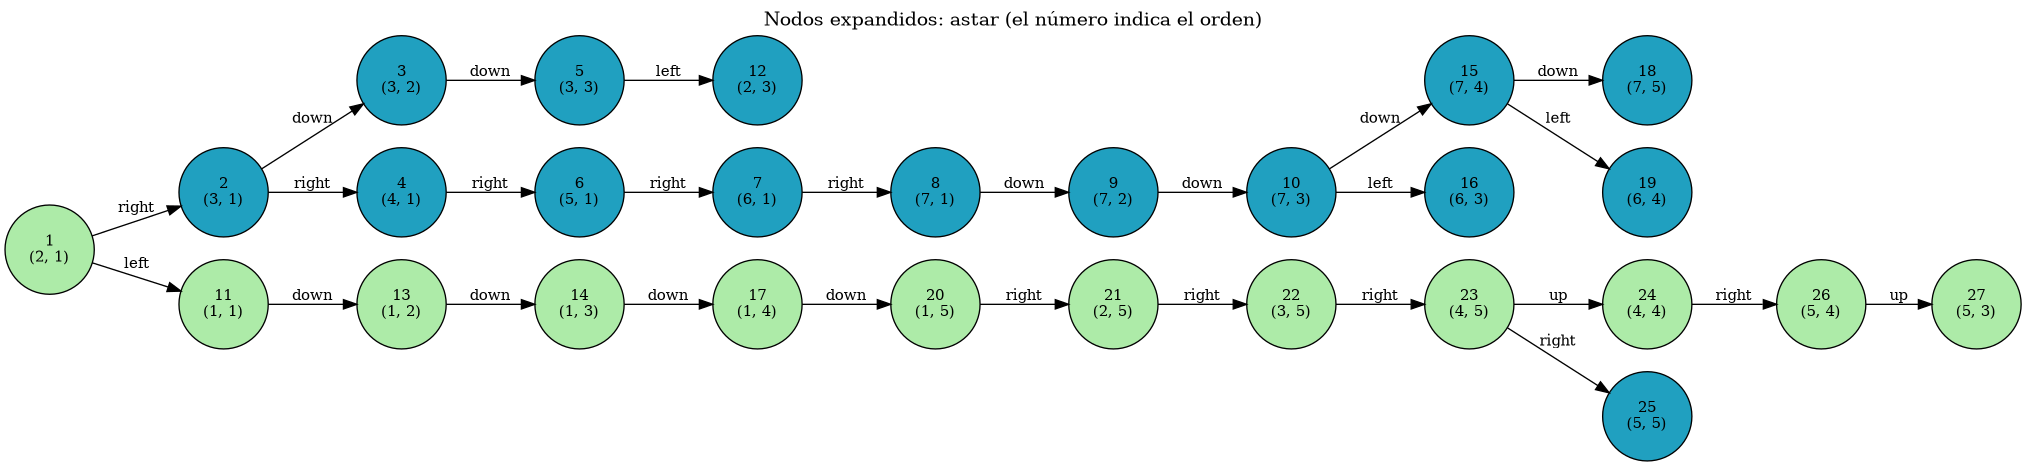

In [71]:
# Configuración y llamada para el caso 2
# Se utiliza el mismo mapa pero se varían los costes

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 4.0,
}



algorithms=(breadth_first,uniform_cost,astar)
main (MAP_ASCII,COSTS,algorithms,viewer_factory=ExpandedTreeViewer)

Heurística 1

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <

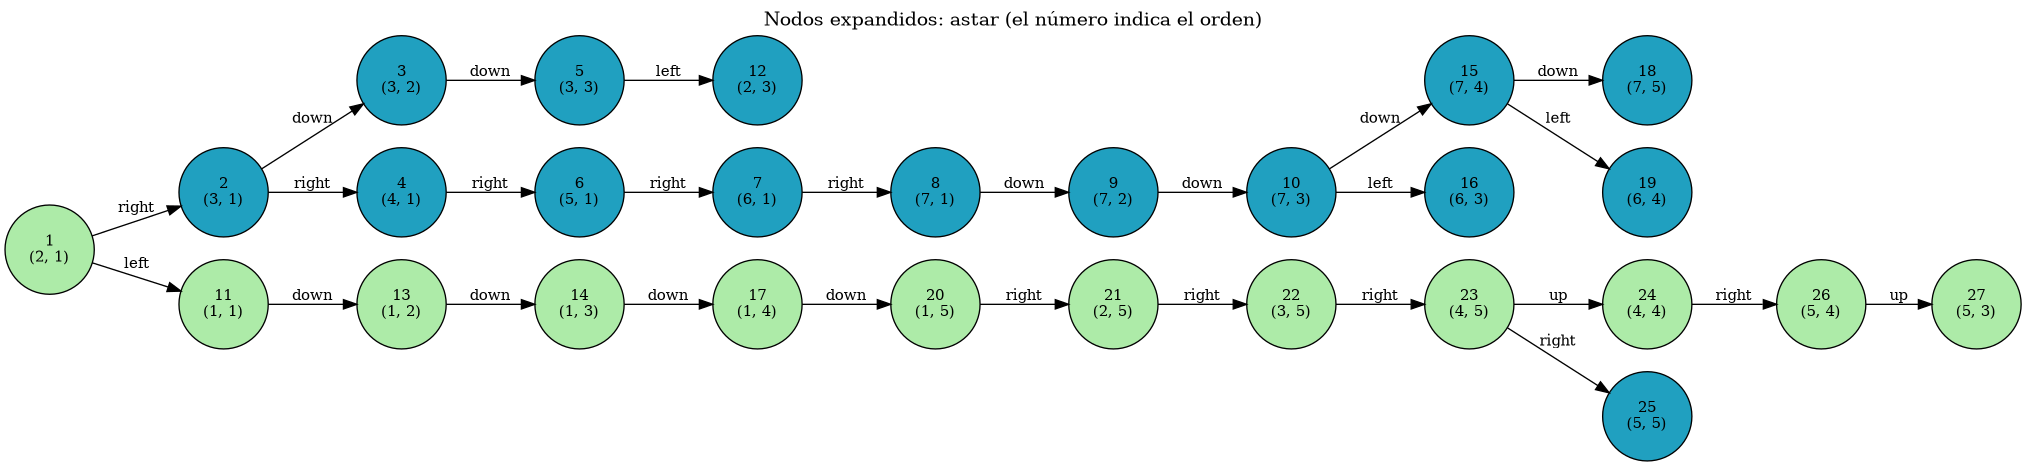

Heurística 2

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <

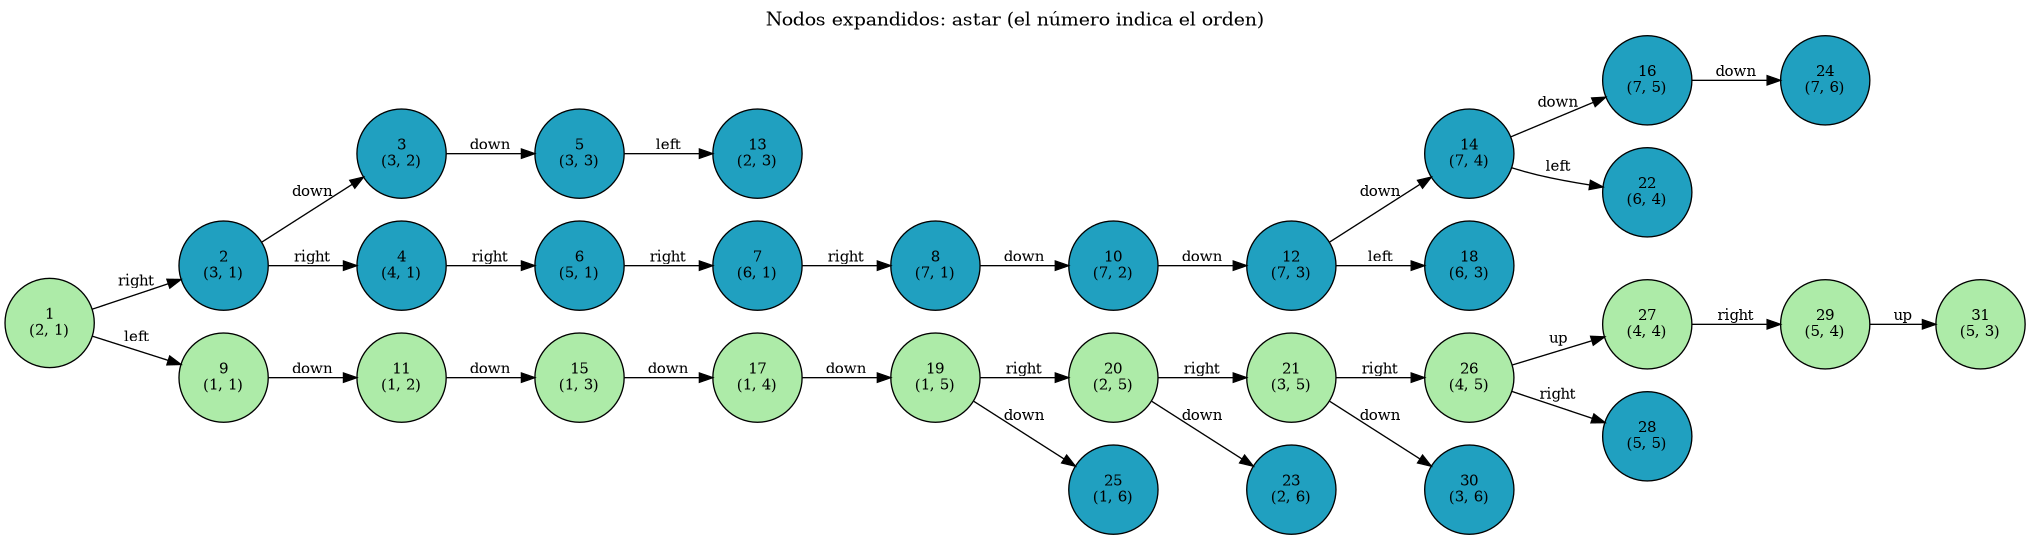

Heurística 3

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(3, 2)>, Node <

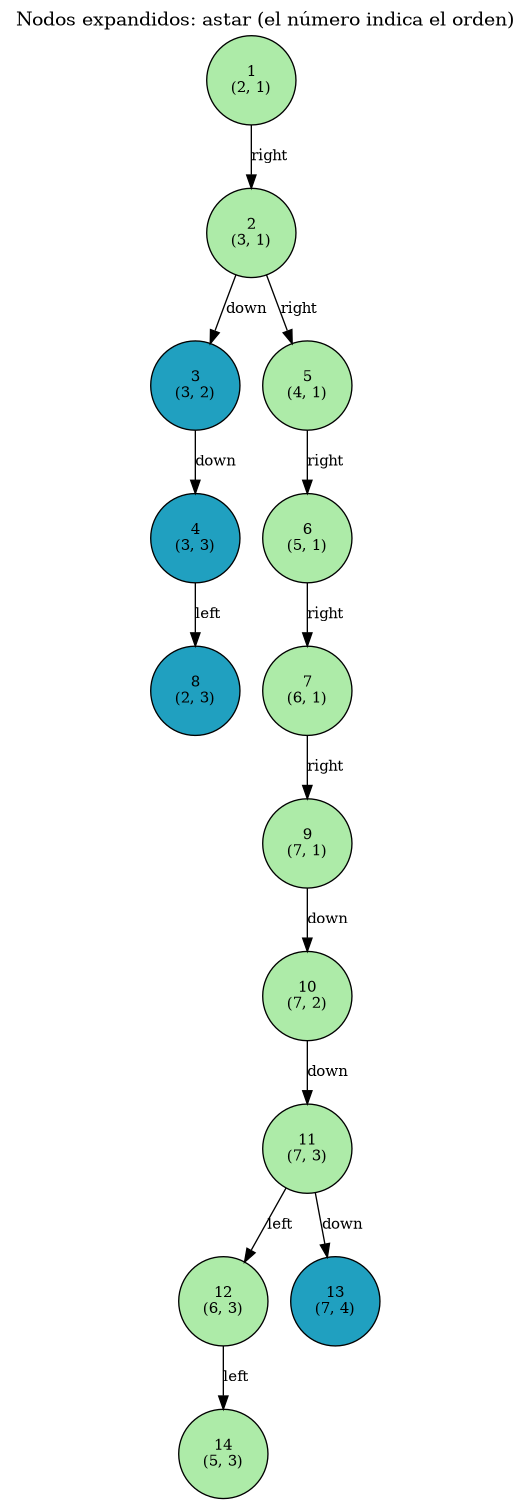

In [72]:

# Configuración y llamada para el caso 3
# Se utiliza el mismo mapa y se usan diferentes heurísticas

MAP_ASCII=MAP_ASCII_ORIG
COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 4.0,
}

algorithms=(astar,)
print ("Heurística 1\n")
main (MAP_ASCII,COSTS,algorithms,1,viewer_factory=ExpandedTreeViewer)
print ("Heurística 2\n")
main (MAP_ASCII,COSTS,algorithms,2,viewer_factory=ExpandedTreeViewer)
print ("Heurística 3\n")
main (MAP_ASCII,COSTS,algorithms,3,viewer_factory=ExpandedTreeViewer,rankdirs={'astar': 'TB'})



UCS (referencia)

Experimento con algoritmo <function uniform_cost at 0x7d1e6c135940>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(4, 

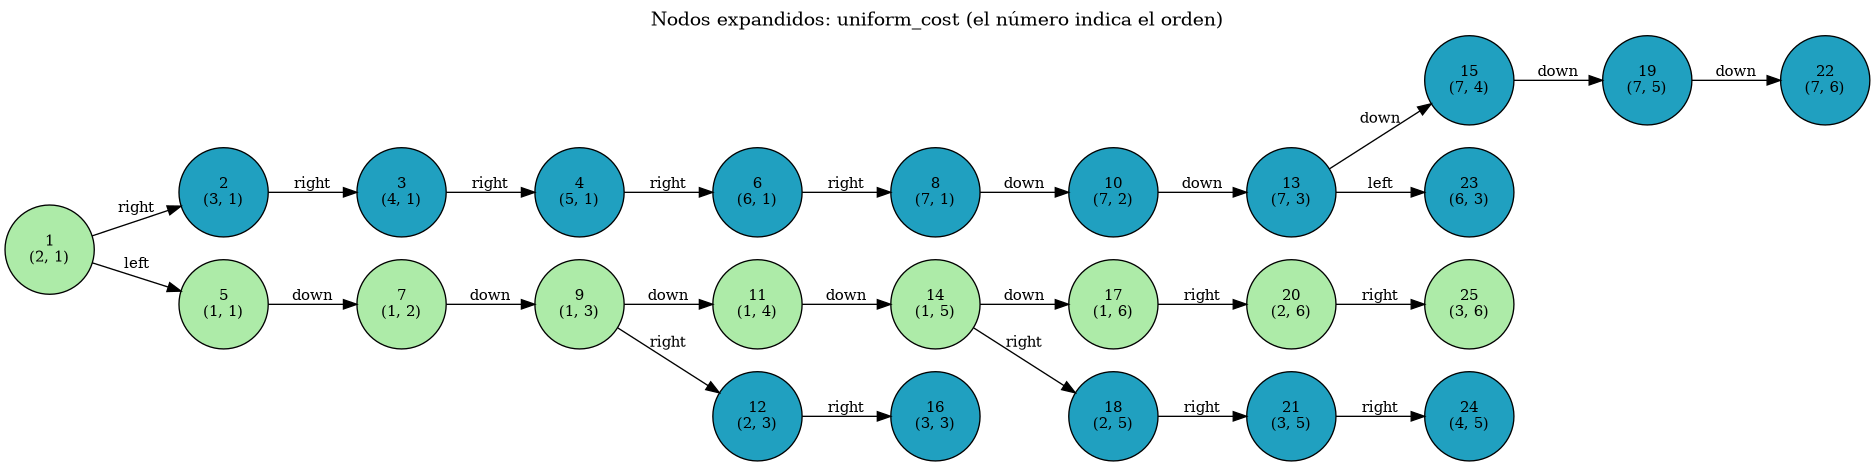

Heurística 1

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(4, 1)>, Node <

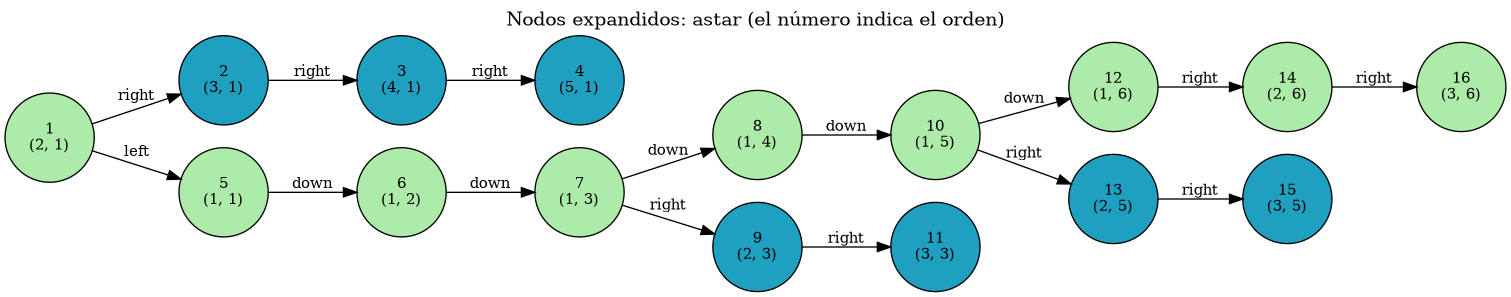

Heurística 2

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(4, 1)>, Node <

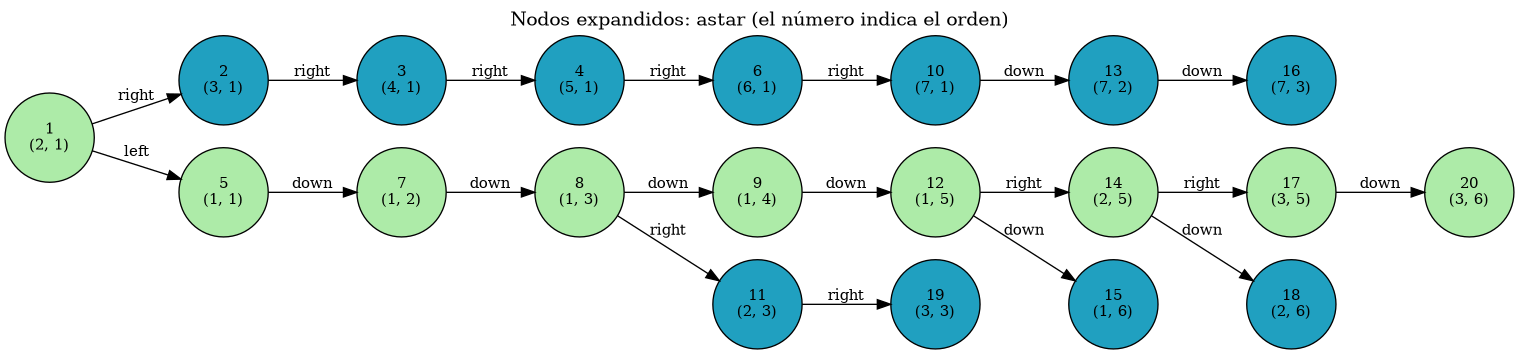

Heurística 3

Experimento con algoritmo <function astar at 0x7d1e6c135a80>:
After each step, a prompt will be shown.
On the prompt, you can just press Enter to continue to the next step.
But you can also have this commands:
(write the command you want to use and then press Enter)
* h: get help.
* g PATH_TO_PNG_IMAGE: create png with graph of the current state.
* e: run non-interactively to the end of the algorithm.
* s: show statistics of the execution (max fringe size, visited nodes).
* q: quit program.
EVENT: started
Algorithm just started.
EVENT: new_iteration
New iteration with 1 elements in the fringe:
[Node <(2, 1)>]
EVENT: chosen_node
Chosen node: Node <(2, 1)>
Not goal
EVENT: expanded
Expanded [Node <(2, 1)>]
Successors: [[Node <(3, 1)>, Node <(1, 1)>]]
EVENT: new_iteration
New iteration with 2 elements in the fringe:
[Node <(3, 1)>, Node <(1, 1)>]
EVENT: chosen_node
Chosen node: Node <(3, 1)>
Not goal
EVENT: expanded
Expanded [Node <(3, 1)>]
Successors: [[Node <(4, 1)>, Node <

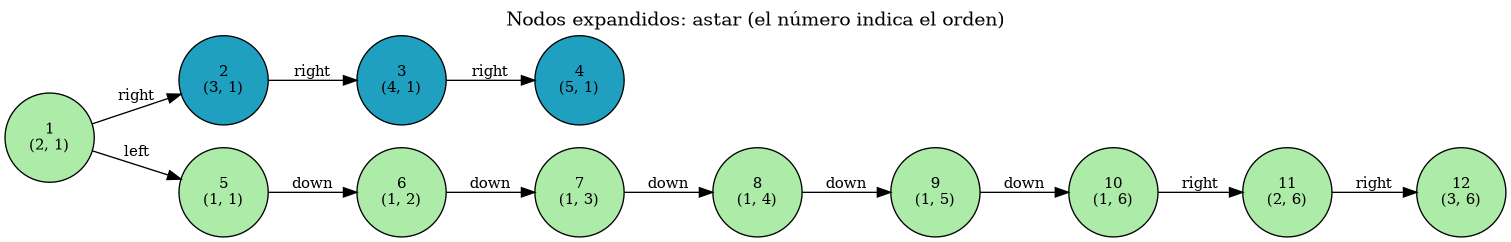

In [73]:
# Configuración y llamada para la pregunta 7 del caso 3
# Mapa diseñado para comprobar si la respuesta 4 varía al cambiar las paredes
# y las posiciones de inicio (T) y fin (P). Se mantienen los costes del caso 3
# y se ejecuta UCS como referencia del coste óptimo

# Se cambian las paredes y la posición del paquete (P); la furgoneta (T) se mantiene
MAP_ASCII_P7 = """
#########
# T     #
# ##### #
#   #   #
# ## ## #
#    #  #
#  P    #
#########
"""

COSTS = {
    "up": 1.0,
    "down": 1.0,
    "right": 1.0,
    "left": 4.0,
}

print ("UCS (referencia)\n")
main (MAP_ASCII_P7,COSTS,(uniform_cost,),viewer_factory=ExpandedTreeViewer)
print ("Heurística 1\n")
main (MAP_ASCII_P7,COSTS,(astar,),1,viewer_factory=ExpandedTreeViewer)
print ("Heurística 2\n")
main (MAP_ASCII_P7,COSTS,(astar,),2,viewer_factory=ExpandedTreeViewer)
print ("Heurística 3\n")
main (MAP_ASCII_P7,COSTS,(astar,),3,viewer_factory=ExpandedTreeViewer)
